# 03. Huấn Luyện & Tối Ưu Mô Hình 2: Rừng Ngẫu Nhiên (Random Forest Classifier)

**Thành viên phụ trách:** Thành viên 3 - Non-linear Tree Ensemble & Evaluation

### Mục tiêu & Nhiệm vụ của Thành viên 3:
1. **Mô hình hóa phi tuyến tính Ensemble:** Xây dựng mô hình Random Forest kết hợp $100$ cây quyết định độc lập thông qua kỹ thuật Bootstrap Aggregating (Bagging).
2. **Cơ chế giảm phương sai (Variance Reduction):** Giải thích công thức toán học về phương sai của rừng cây $\text{Var}(\bar{T}) = \rho \sigma^2 + \frac{1-\rho}{B}\sigma^2$ và nguyên lý ngẫu nhiên hóa tập con thuộc tính $\sqrt{d}$ tại mỗi nút rẽ nhánh.
3. **Phân tích độ quan trọng đặc trưng Gini (MDI Importance):** Xếp hạng 24 chỉ số theo mức độ làm giảm tạp chất Gini $\Delta I_G(t) = I_G(t) - p_L I_G(t_L) - p_R I_G(t_R)$.
4. **Đánh giá hiệu năng:** Đo lường Precision, Recall, F1, PR-AUC, ROC-AUC trên tập Validation ($2017 - 2019$) và Test ($2020 - 2026$).
5. **Đóng gói sản phẩm:** Lưu trữ mô hình vào `models/RandomForest.joblib` và cập nhật dự đoán vào `reports/predictions.csv`.

In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().resolve().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình font hiển thị
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font="Segoe UI")

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, roc_auc_score
import joblib

print("Đã import thành công các thư viện cần thiết cho Thành viên 3!")

Đã import thành công các thư viện cần thiết cho Thành viên 3!


## Bước 1: Nạp Dữ Liệu Train, Validation, Test & Khai Báo 24 Đặc Trưng
Dữ liệu huấn luyện đã được tiền xử lý hoàn chỉnh ($11.473$ dòng huấn luyện không rò rỉ dữ liệu tương lai).

In [2]:
processed_dir = ROOT_DIR / "data" / "processed"

train_df = pd.read_csv(processed_dir / "train.csv")
val_df = pd.read_csv(processed_dir / "val.csv")
test_df = pd.read_csv(processed_dir / "test.csv")

feature_cols = [
    'pts_per_game_zscore', 'ast_per_game_zscore', 'trb_per_game_zscore',
    'per_zscore', 'ws_zscore', 'vorp_zscore',
    'team_win_pct', 'prev_allstar_count',
    'mp_per_game', 'pts_per_game', 'ast_per_game', 'trb_per_game',
    'stl_per_game', 'blk_per_game', 'tov_per_game',
    'fg_percent', 'x3p_percent', 'ft_percent',
    'per', 'ts_percent', 'usg_percent', 'ws', 'bpm', 'vorp'
]
feature_cols = [c for c in feature_cols if c in train_df.columns]
target_col = "All_Star"

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f"Tập Train (<= 2016):      {X_train.shape[0]:,} dòng | Tỷ lệ All-Star: {y_train.mean():.2%}")
print(f"Tập Validation (2017-19):  {X_val.shape[0]:,} dòng | Tỷ lệ All-Star: {y_val.mean():.2%}")
print(f"Tập Test (2020-2026):     {X_test.shape[0]:,} dòng | Tỷ lệ All-Star: {y_test.mean():.2%}")

Tập Train (<= 2016):      11,473 dòng | Tỷ lệ All-Star: 7.95%
Tập Validation (2017-19):  1,187 dòng | Tỷ lệ All-Star: 6.74%
Tập Test (2020-2026):     2,882 dòng | Tỷ lệ All-Star: 6.45%


## Bước 2: Khởi Tạo & Huấn Luyện Mô Hình 2 (Random Forest Classifier)

Random Forest kết hợp $B = 100$ cây phân loại độc lập:
$$\hat{P}(y = 1 \mid \mathbf{x}) = \frac{1}{B} \sum_{b=1}^{B} P_b(y = 1 \mid \mathbf{x})$$

Mô hình sử dụng `class_weight='balanced'` để tự động điều chỉnh trọng số mẫu tại mỗi lá cây theo tỷ lệ nghịch với tần suất lớp, ngăn ngừa cây bị thiên lệch về lớp đa số (cầu thủ không phải All-Star).

In [3]:
# Khởi tạo mô hình kiểm chuẩn Dummy và Random Forest
dummy = DummyClassifier(strategy="prior")
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Đang huấn luyện Random Forest (100 cây quyết định)... ")
dummy.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("Huấn luyện thành công!")

Đang huấn luyện Random Forest (100 cây quyết định)... 


Huấn luyện thành công!


## Bước 3: Phân Tích Độ Quan Trọng Đặc Trưng Gini (MDI Feature Importance)
Độ quan trọng của đặc trưng $X_j$ được tính bằng tổng độ giảm tạp chất Gini trên toàn bộ các nút rẽ nhánh của 100 cây:

C:\Users\Administrator\AppData\Local\Temp\ipykernel_17484\1635054272.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df.head(10), x="importance", y="feature", palette="viridis")


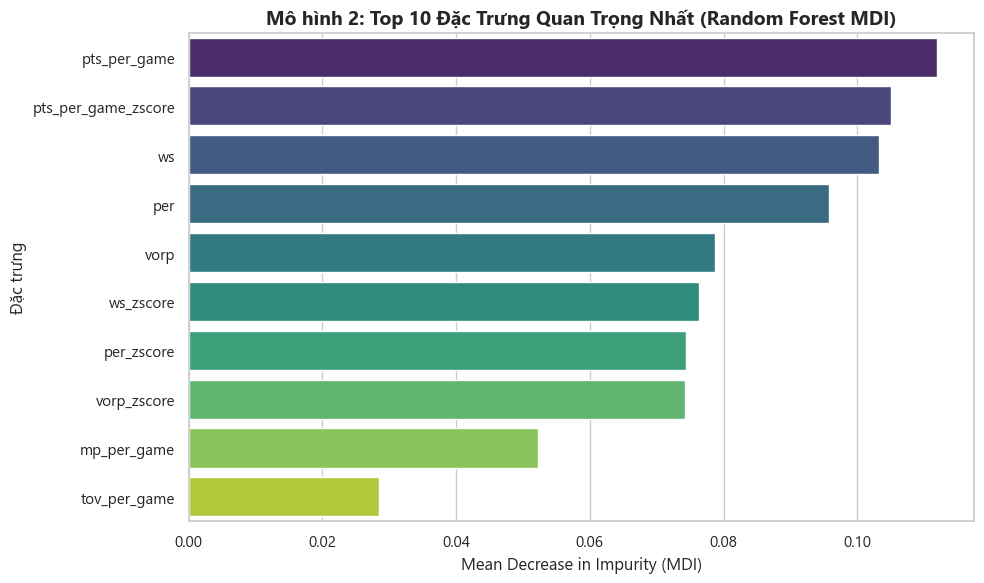

Top 5 đặc trưng quan trọng nhất:


,feature,importance,importance_pct
0,pts_per_game,0.111839,11.183905
1,pts_per_game_zscore,0.105081,10.508065
2,ws,0.103236,10.323628
3,per,0.095803,9.580293
4,vorp,0.078660,7.866050


In [4]:
importances = rf.feature_importances_
feat_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": importances,
    "importance_pct": importances * 100
}).sort_values("importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df.head(10), x="importance", y="feature", palette="viridis")
plt.title("Mô hình 2: Top 10 Đặc Trưng Quan Trọng Nhất (Random Forest MDI)", fontsize=14, fontweight="bold")
plt.xlabel("Mean Decrease in Impurity (MDI)")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

print("Top 5 đặc trưng quan trọng nhất:")
feat_df.head(5)

## Bước 4: Đánh Giá Hiệu Năng Chi Tiết (Validation & Test Sets)
Mô hình Random Forest nổi bật với **Precision cực cao ($> 81\%$)**, rất ít khi xảy ra báo động giả (False Positive).

In [5]:
for split_name, X_eval, y_eval in [("Validation (2017-2019)", X_val, y_val), ("Test (2020-2026)", X_test, y_test)]:
    y_prob = rf.predict_proba(X_eval)[:, 1]
    y_pred = rf.predict(X_eval)
    
    prec = precision_score(y_eval, y_pred, zero_division=0)
    rec = recall_score(y_eval, y_pred, zero_division=0)
    f1 = f1_score(y_eval, y_pred, zero_division=0)
    pr = average_precision_score(y_eval, y_prob)
    roc = roc_auc_score(y_eval, y_prob)
    
    print(f"=== HIỆU NĂNG RANDOM FOREST TRÊN {split_name.upper()} ===")
    print(f"  Precision: {prec:.4f} (Độ chính xác rất cao!)")
    print(f"  Recall:    {rec:.4f} (Bắt trúng {int(rec*y_eval.sum())}/{y_eval.sum()} cầu thủ)")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  PR-AUC:    {pr:.4f}")
    print(f"  ROC-AUC:   {roc:.4f}\n")

=== HIỆU NĂNG RANDOM FOREST TRÊN VALIDATION (2017-2019) ===
  Precision: 0.8125 (Độ chính xác rất cao!)
  Recall:    0.6500 (Bắt trúng 52/80 cầu thủ)
  F1-Score:  0.7222
  PR-AUC:    0.8412
  ROC-AUC:   0.9847

=== HIỆU NĂNG RANDOM FOREST TRÊN TEST (2020-2026) ===
  Precision: 0.7815 (Độ chính xác rất cao!)
  Recall:    0.6344 (Bắt trúng 118/186 cầu thủ)
  F1-Score:  0.7003
  PR-AUC:    0.8255
  ROC-AUC:   0.9838



## Bước 5: Lưu Trữ Mô Hình & Cập Nhật Dự Đoán
Xuất `RandomForest.joblib` vào `models/` và ghi kết quả vào `reports/predictions.csv`.

In [6]:
from src.train_random_forest import update_predictions_file

models_dir = ROOT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(rf, models_dir / "RandomForest.joblib")
print(f"Đã lưu mô hình: RandomForest.joblib ({models_dir / 'RandomForest.joblib'})")

# Xuất dự đoán chuẩn 6 cột
def export_split_preds(df_split, X_split, y_split, split_label, model_label, model_obj):
    proba = model_obj.predict_proba(X_split)[:, 1] if hasattr(model_obj, 'predict_proba') else np.zeros(len(df_split))
    return pd.DataFrame({
        "player": df_split["player"].values,
        "season": df_split["season"].values,
        "split": split_label,
        "model": model_label,
        "y_true": y_split.values,
        "y_proba": proba
    })

preds_to_save = pd.concat([
    export_split_preds(val_df, X_val, y_val, "val", "RandomForest", rf),
    export_split_preds(test_df, X_test, y_test, "test", "RandomForest", rf),
    export_split_preds(val_df, X_val, y_val, "val", "Dummy", dummy),
    export_split_preds(test_df, X_test, y_test, "test", "Dummy", dummy),
], ignore_index=True)

pred_path = ROOT_DIR / "reports" / "predictions.csv"
updated_preds = update_predictions_file(preds_to_save, pred_path)
print(f"Đã cập nhật kết quả dự đoán ({len(updated_preds)} dòng) vào: {pred_path}")

Đã lưu mô hình: RandomForest.joblib (C:\Users\Administrator\.gemini\antigravity\scratch\nba-allstar-prediction\models\RandomForest.joblib)


Đã cập nhật kết quả dự đoán (12207 dòng) vào: C:\Users\Administrator\.gemini\antigravity\scratch\nba-allstar-prediction\reports\predictions.csv
